# 02. 센서 분포·추이·공정 조건 EDA

전체 장비의 범위·결측은 01 Notebook에서 집계했습니다. 이 Notebook은 대용량 추가 처리를 줄이기 위해 **사전 고정한 01M01 전체 3,124,704행**을 대상으로 분포와 상관을 집계합니다. 무작위 표본은 사용하지 않습니다. 히스토그램과 장기 추이만 고정 크기 집계로 축약하며, 고장 직전 시계열은 03에서 원래 순서로 분석합니다.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd()/"src").is_dir() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
assert Path(sys.prefix).name.lower()=="phm2018", sys.executable
assert sys.version_info[:2]==(3,11), sys.version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.eda_common import DATA, OUT, SENSORS, FAULTS, SOURCE_URL, overview, read_json, load_faults, snapshot
from src.eda_detail import representative, audit_time_keys, audit_tagged_ttf, horizon_labels
from src import eda_plots as plots
plots.setup()
pd.set_option("display.max_columns",30)
pd.set_option("display.max_rows",80)
print("실행 Python:",sys.executable)
print("Python 버전:",sys.version.split()[0])

실행 Python: C:\Users\fl27\anaconda3\envs\phm2018\python.exe
Python 버전: 3.11.18


In [2]:
result=overview()
detail=representative()
print("대표 파일:",detail["file"],"/ 장비:",detail["Tool"],"/ 관측 수:",detail["rows"])
display(pd.DataFrame(result["sensor_by_tool"]).query("Tool == @detail['Tool']") if False else pd.DataFrame([x for x in result["sensor_by_tool"] if x["Tool"]==detail["Tool"]]))

검증된 입력/코드 메타데이터와 일치하는 로컬 집계 캐시 사용


대표 01M01: 3,124,704행 분포/상관 집계; 선택 event=11, 충분한 윈도 4/4
대표 파일: 01_M01_DC_train.csv / 장비: 01M01 / 관측 수: 3124704


,sensor,rows,finite,missing,missing_ratio,infinite,min,max,mean,std,read_dtype,Tool
0,FLOWCOOLPRESSURE,3124704,3124704,0,0.0,0,-1.219059,10.085588,0.018375,1.173330,float64,01M01
1,FLOWCOOLFLOWRATE,3124704,3124704,0,0.0,0,-1.449477,2.673885,-0.028938,1.011795,float64,01M01
2,IONGAUGEPRESSURE,3124704,3124704,0,0.0,0,-1.357306,10.435943,-0.007511,1.025277,float64,01M01
3,ETCHBEAMCURRENT,3124704,3124704,0,0.0,0,-1.154544,3.273169,-0.027063,1.001527,float64,01M01
4,ETCHBEAMVOLTAGE,3124704,3124704,0,0.0,0,-1.128402,2.487017,-0.023145,0.999918,float64,01M01
5,ETCHSUPPRESSORCURRENT,3124704,3124704,0,0.0,0,-1.145790,20.370074,0.011572,1.031476,float64,01M01


## 센서별 히스토그램

대표 장비 전체 유한값을 센서마다 120개 동일 폭 bin으로 집계했습니다. 긴 꼬리의 빈도를 보기 위해 y축을 로그로 표시합니다. 특정 물리 단위를 임의로 붙이지 않습니다.

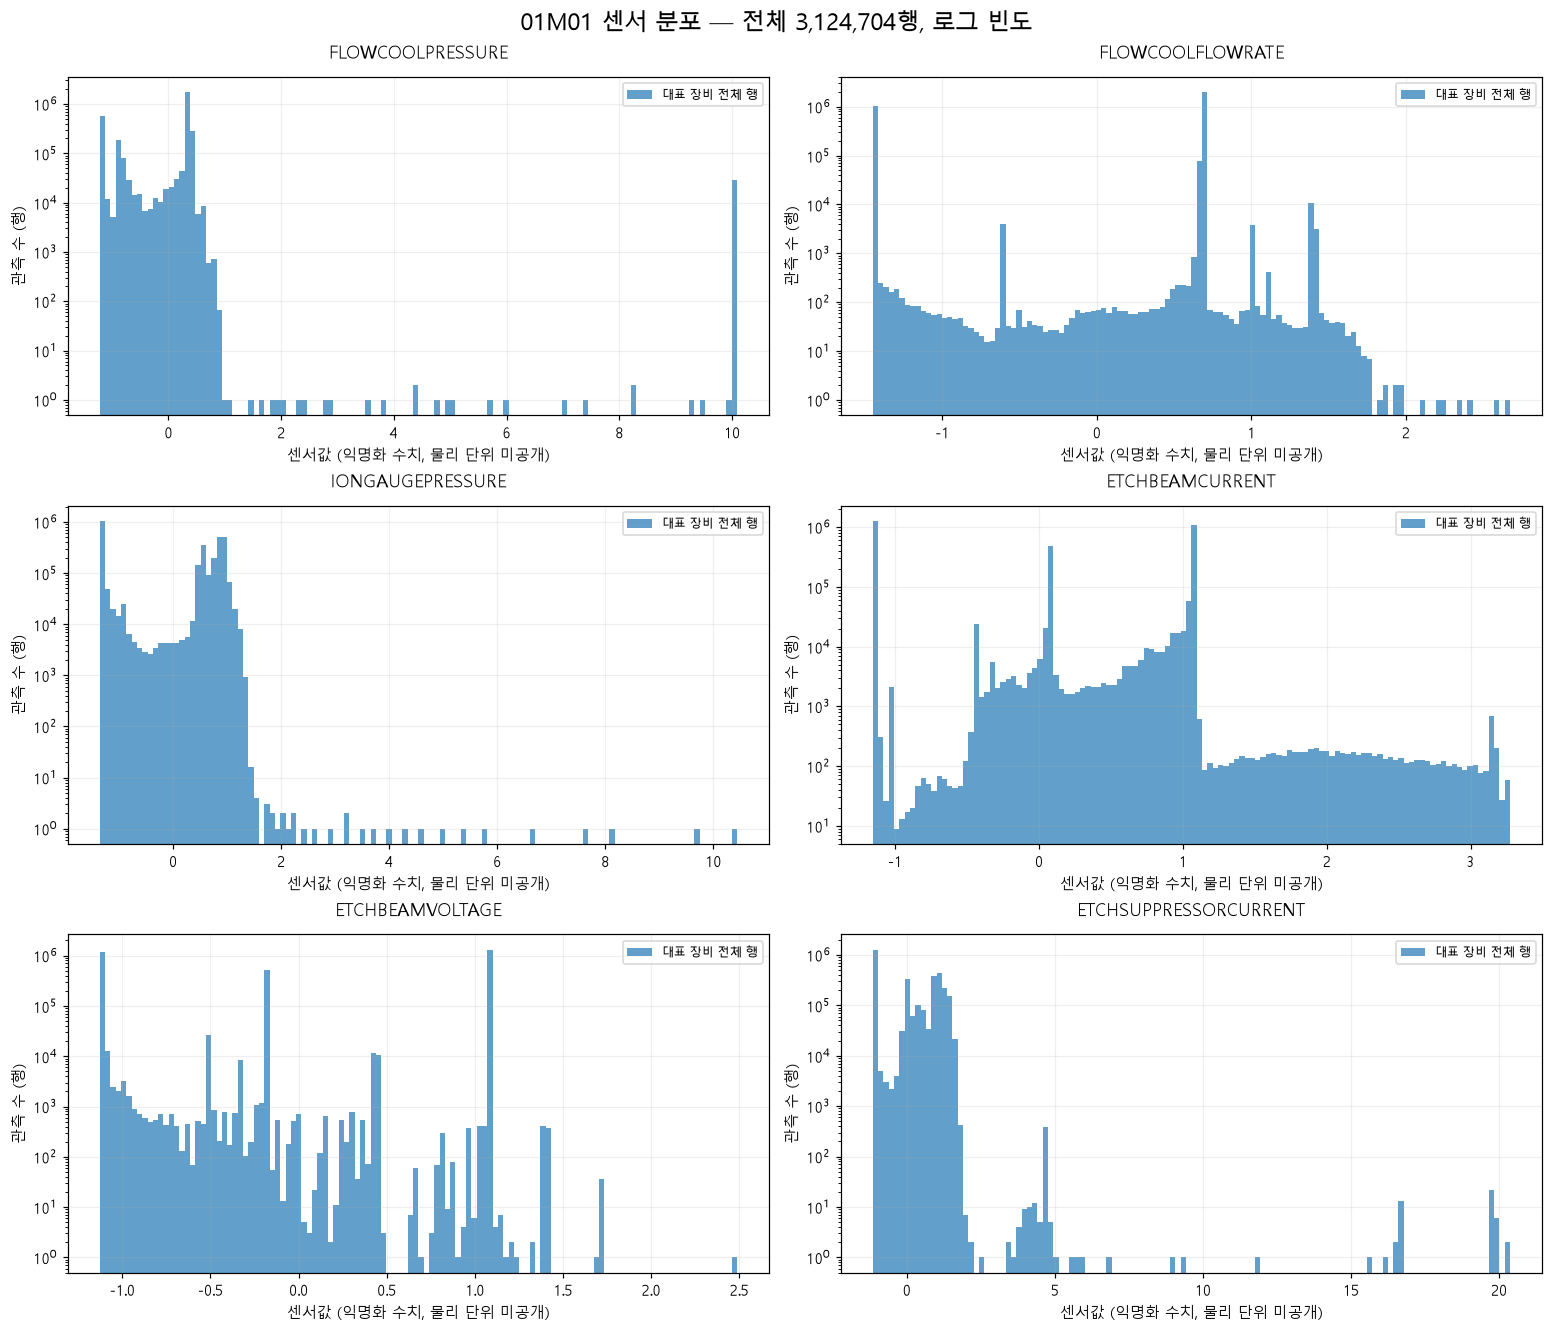

분포의 여러 봉우리와 경계 부근 집중은 공정 상태 혼합의 영향을 받을 수 있습니다. 익명화 수치가 음수라는 이유만으로 이상값으로 처리하지 않습니다. 아래 공정 조건별 평균과 함께 해석합니다.

In [3]:
plots.histograms(detail)
display(Markdown("분포의 여러 봉우리와 경계 부근 집중은 공정 상태 혼합의 영향을 받을 수 있습니다. 익명화 수치가 음수라는 이유만으로 이상값으로 처리하지 않습니다. 아래 공정 조건별 평균과 함께 해석합니다."))

## 시간 추이

대표 장비의 전체 측정 기간을 약 2,000개 시간 bin으로 집계한 평균입니다. 원래 관측이 없는 bin은 연결하지 않습니다. bin 내부의 짧은 공백과 급격한 변화는 축약될 수 있으므로 전조 판단에는 아래 장기 평균을 쓰지 않습니다.

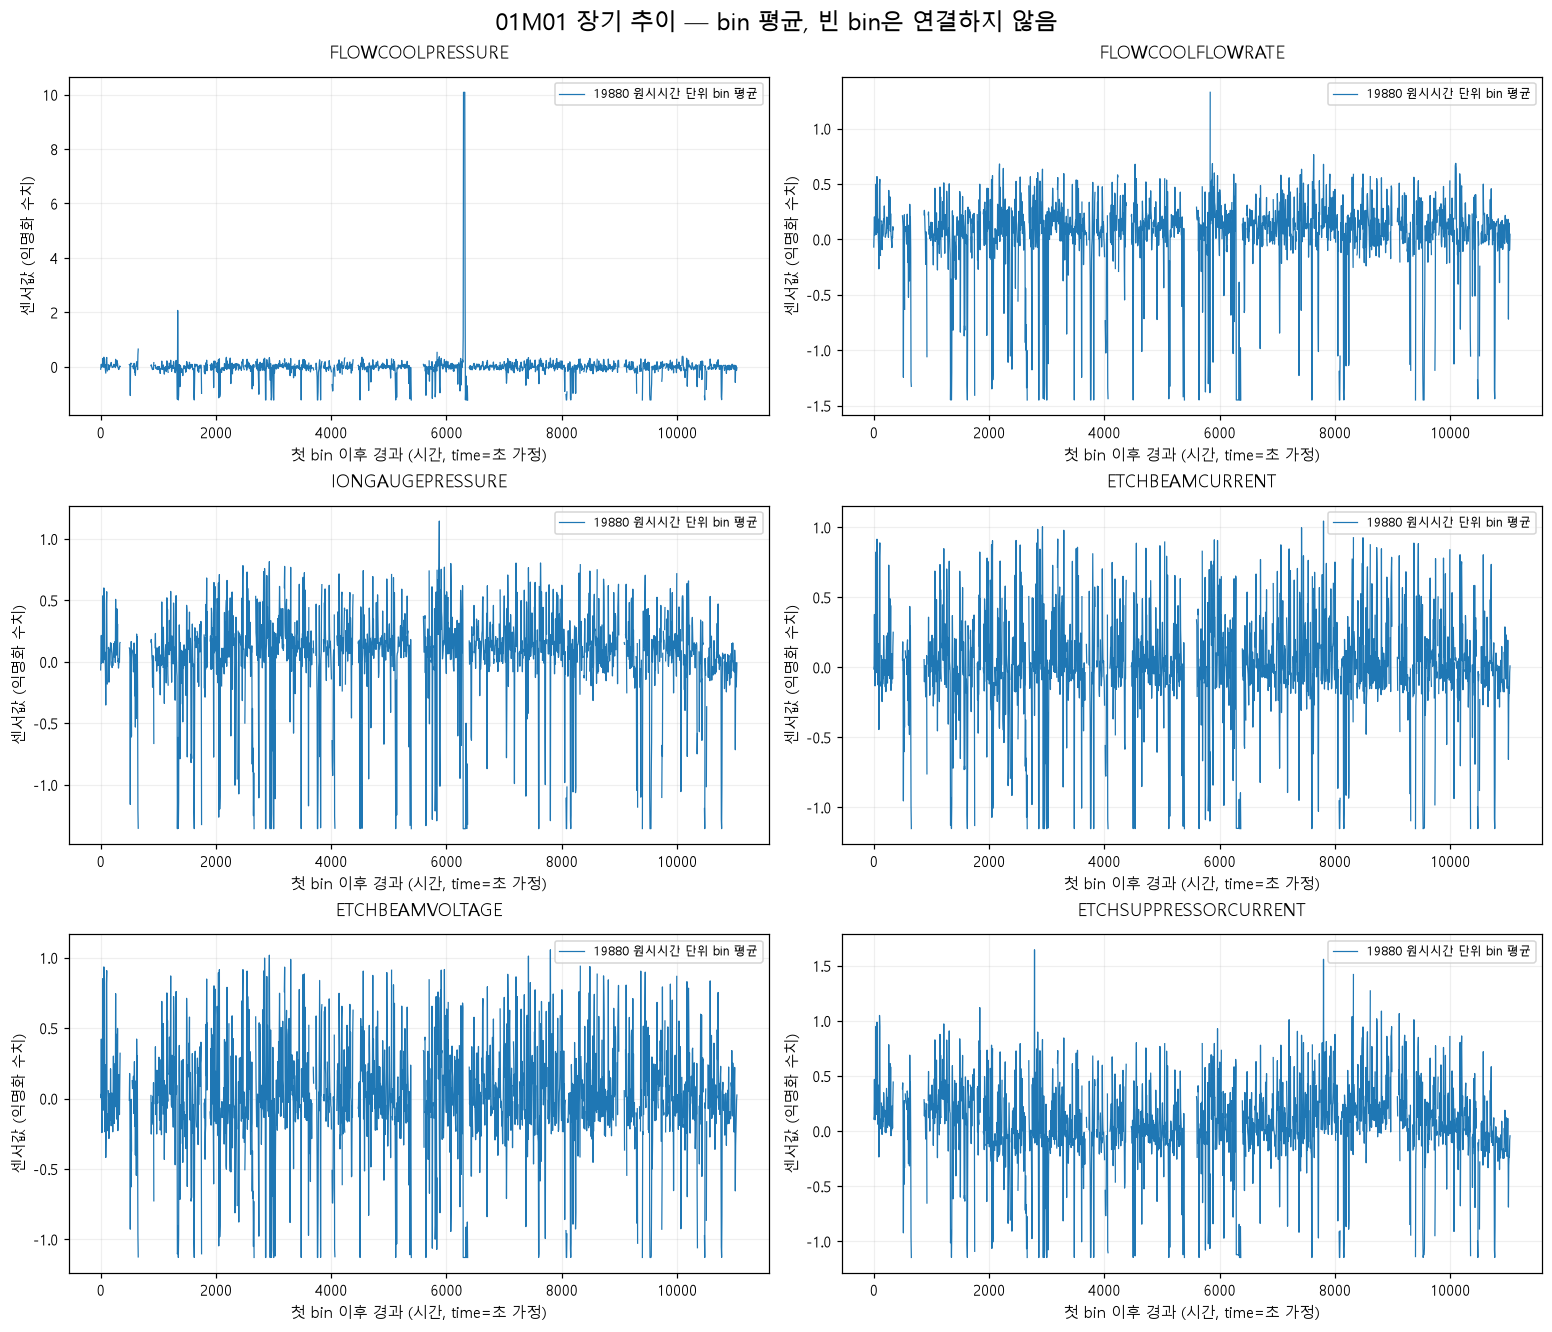

시간 bin 폭: 19880.0 원시시간 단위


장기 평균은 운전 조건과 가동 비율의 변화도 반영합니다. 압력이나 전류의 상승·하락을 장기 평균 그래프만으로 고장 진행으로 단정하지 않습니다.

In [4]:
plots.timeline(detail)
print("시간 bin 폭:",detail["timeline_bin_raw"],"원시시간 단위")
display(Markdown("장기 평균은 운전 조건과 가동 비율의 변화도 반영합니다. 압력이나 전류의 상승·하락을 장기 평균 그래프만으로 고장 진행으로 단정하지 않습니다."))

## 결측 및 이상값 후보

히스토그램 내 선형 보간으로 Q1/Q3를 근사하고 `Q1-1.5×IQR`, `Q3+1.5×IQR` 경계를 정했습니다. 그 경계 밖의 행 수는 대표 파일을 다시 청크 순회하여 정확히 셉니다. 분위수 경계 자체는 근사이며, 통계적 꼬리 후보는 고장 라벨이나 물리 오류 판정이 아닙니다. 삭제·클리핑은 하지 않습니다.

In [5]:
outliers=pd.DataFrame(detail["outlier_fences"]).T
outliers["flagged_ratio"]=outliers.flagged/detail["rows"]
display(outliers)
display(Markdown("IQR 경계는 공정 상태를 섞으면 정상 운전의 드문 상태도 표시할 수 있습니다. 모델링 전에는 장비·Recipe·Stage별 기준과 데이터 사전을 확인해야 합니다. 전체 장비의 IQR 이상값 수는 이번에 계산하지 않았습니다."))

,q1_hist_approx,q3_hist_approx,lower,upper,flagged,flagged_ratio
FLOWCOOLPRESSURE,-0.843219,0.357835,-2.644801,2.159417,28820.0,0.009223
FLOWCOOLFLOWRATE,-1.423884,0.702001,-4.612712,3.890829,0.0,0.000000
IONGAUGEPRESSURE,-1.283628,0.870589,-4.514955,4.101916,10.0,0.000003
ETCHBEAMCURRENT,-1.131688,1.069809,-4.433932,4.372054,0.0,0.000000
ETCHBEAMVOLTAGE,-1.108816,1.083051,-4.396615,4.370850,0.0,0.000000
ETCHSUPPRESSORCURRENT,-1.034727,1.027773,-4.128478,4.121524,476.0,0.000152


IQR 경계는 공정 상태를 섞으면 정상 운전의 드문 상태도 표시할 수 있습니다. 모델링 전에는 장비·Recipe·Stage별 기준과 데이터 사전을 확인해야 합니다. 전체 장비의 IQR 이상값 수는 이번에 계산하지 않았습니다.

## 주요 센서 상관관계

대표 장비에서 6개 센서가 모두 유한한 행의 합·제곱합·교차곱을 청크별로 누적한 Pearson 상관입니다. 장비 전체에 대한 결과이며 장비 전체를 메모리에 적재하지 않습니다. 공정 조건 혼합과 시계열 자기상관의 영향이 있습니다.

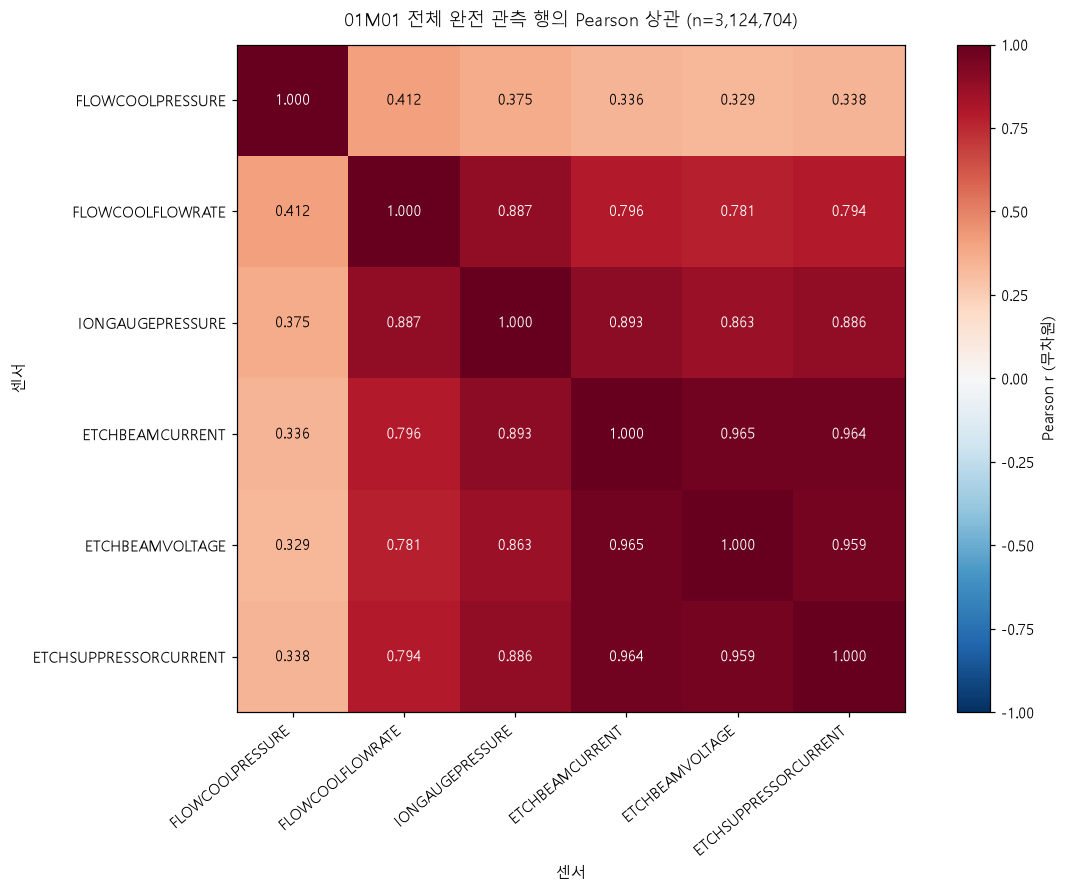

대표 01M01에서 ETCHBEAMCURRENT–ETCHBEAMVOLTAGE 상관은 **0.965**, ETCHBEAMCURRENT–ETCHSUPPRESSORCURRENT는 **0.964**입니다. 높은 공정 동조성을 시사하지만 고장 인과관계나 다른 장비에서의 동일 상관을 입증하지 않습니다.

In [6]:
plots.correlation(detail)
c=np.array(detail["correlation"])
display(Markdown(f"대표 01M01에서 ETCHBEAMCURRENT–ETCHBEAMVOLTAGE 상관은 **{c[3,4]:.3f}**, ETCHBEAMCURRENT–ETCHSUPPRESSORCURRENT는 **{c[3,5]:.3f}**입니다. 높은 공정 동조성을 시사하지만 고장 인과관계나 다른 장비에서의 동일 상관을 입증하지 않습니다."))

## Recipe·Stage별 센서 값 차이

대표 장비에서 관측 수가 많은 10개 Recipe/Stage 조합을 사용합니다. 조건별 평균은 전체 청크에서 집계하며, 표에는 모든 조합의 행 수와 센서 평균을 제공합니다.

,recipe,stage,rows,FLOWCOOLPRESSURE,FLOWCOOLFLOWRATE,IONGAUGEPRESSURE,ETCHBEAMCURRENT,ETCHBEAMVOLTAGE,ETCHSUPPRESSORCURRENT
0,1.0,1.0,943351,-0.189825,-0.195448,-0.104858,-0.052637,0.001992,0.026589
13,0.0,0.0,442612,0.780519,0.258276,0.359789,0.579149,0.605716,0.553798
4,5.0,22.0,179267,-0.287789,-0.315645,-0.472475,-0.425866,-0.277579,-0.411935
17,4.0,16.0,117412,-0.012859,0.127280,0.006061,-0.299612,-0.464446,-0.244881
14,0.0,4.0,98583,-0.080606,-0.063226,0.029174,0.171899,0.213562,0.213757
...,...,...,...,...,...,...,...,...,...
73,0.0,116.0,106,-0.325625,-0.375467,-0.362871,-0.377495,-0.261781,-0.306233
90,16.0,41.0,106,-0.385947,-0.482265,-0.567355,-0.736389,-0.766814,-0.597212
179,2.0,137.0,105,-0.239298,-0.249372,-0.262570,-0.343192,-0.213148,-0.322526
159,3.0,99.0,96,-0.415232,-0.493302,-0.630942,-0.799365,-0.834664,-0.821452


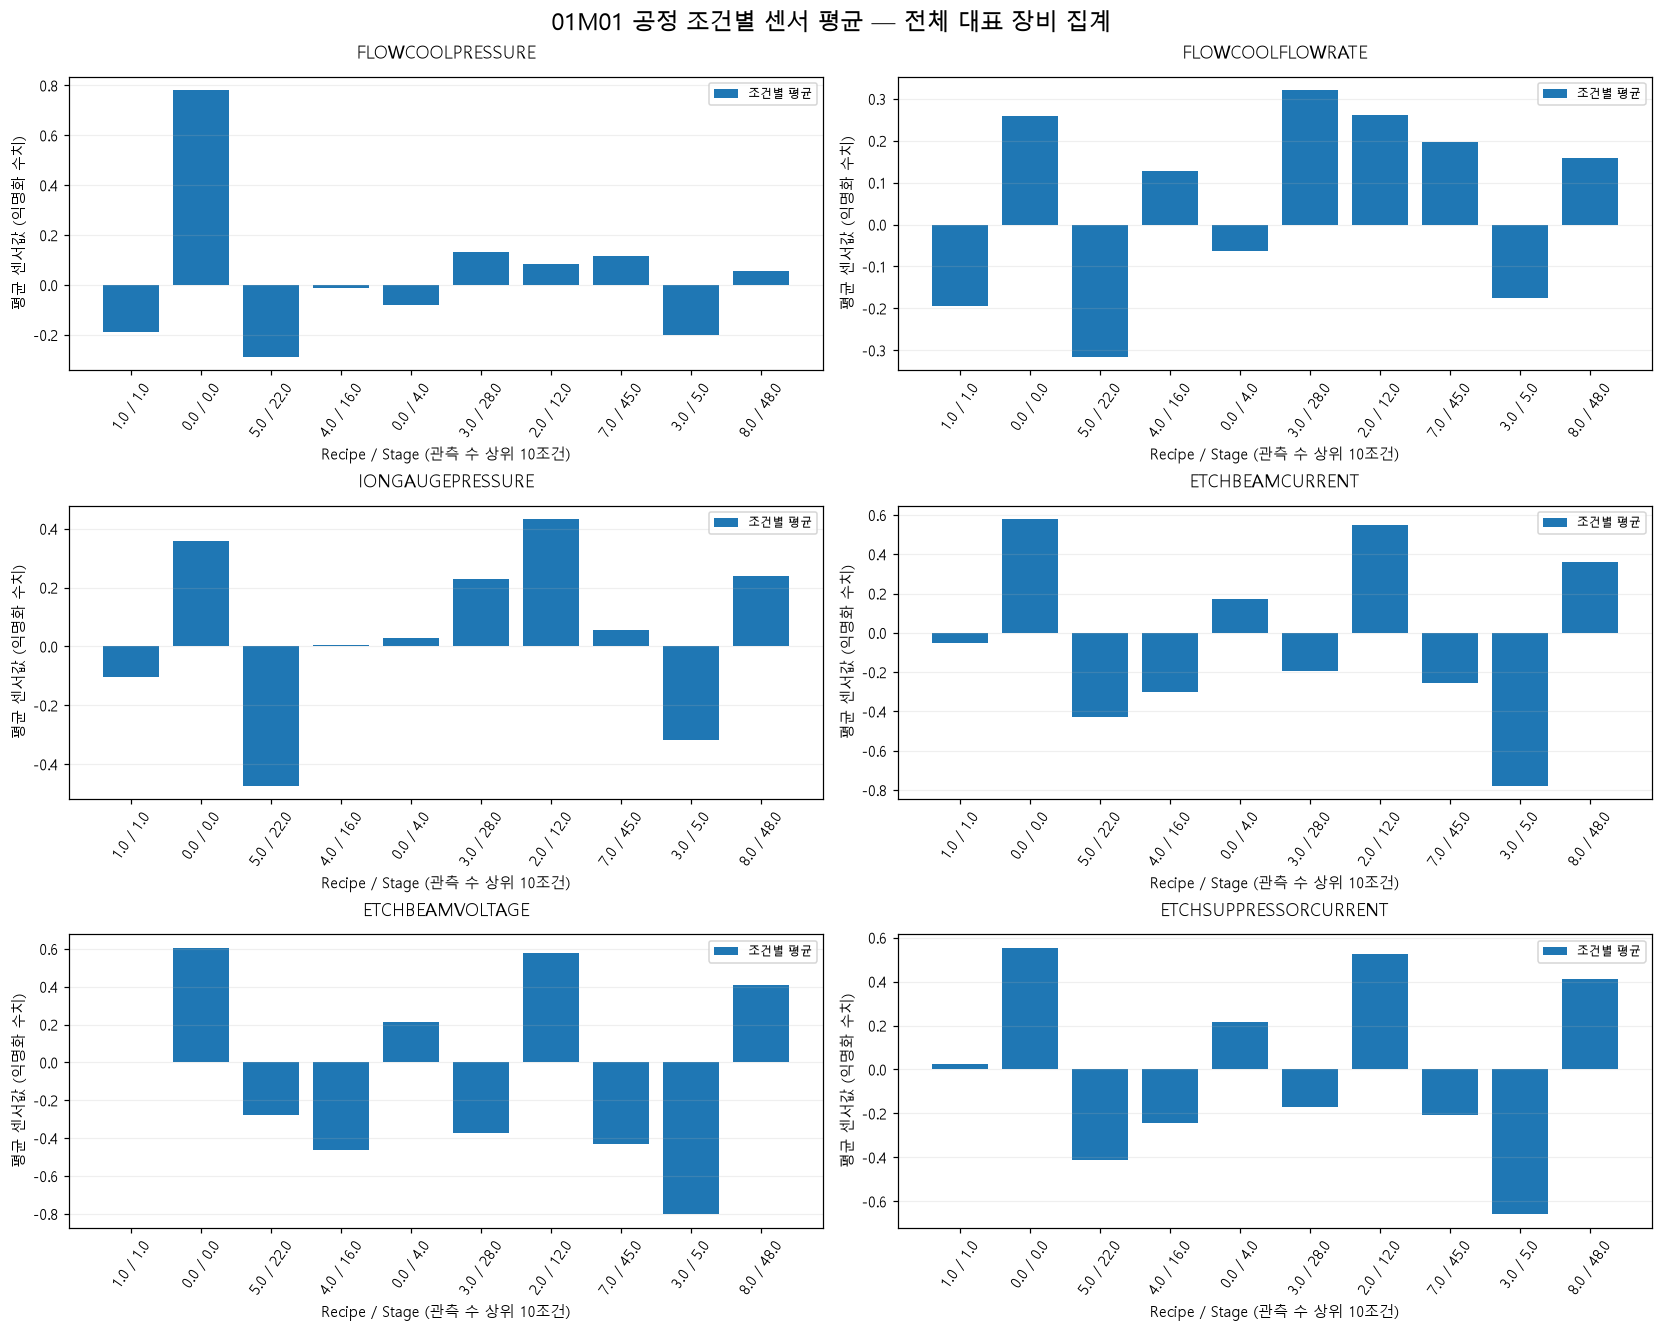

,조건별 평균 최소,조건별 평균 최대
FLOWCOOLPRESSURE,-1.119429,0.780519
FLOWCOOLFLOWRATE,-1.316091,0.571157
IONGAUGEPRESSURE,-1.247135,0.744245
ETCHBEAMCURRENT,-1.086974,0.873569
ETCHBEAMVOLTAGE,-1.077976,0.901967
ETCHSUPPRESSORCURRENT,-1.083428,1.046440


동일 센서도 Recipe/Stage 조합별 평균이 다릅니다. 전체 구간과 고장 전 구간의 평균 차이를 비교할 때 공정 구성 차이를 함께 확인해야 합니다. 03 Notebook에서 실제 구간의 조건별 관측 수와 동일 조건 평균 차이를 대조합니다.

In [7]:
g=pd.DataFrame(result["groups"])
g=g[(g.split=="train")&(g.Tool==detail["Tool"])].sort_values("rows",ascending=False)
display(g[["recipe","stage","rows"]+SENSORS])
plots.process_means(result,detail)
spread=pd.DataFrame({"조건별 평균 최소":g[SENSORS].min(),"조건별 평균 최대":g[SENSORS].max()})
display(spread)
display(Markdown("동일 센서도 Recipe/Stage 조합별 평균이 다릅니다. 전체 구간과 고장 전 구간의 평균 차이를 비교할 때 공정 구성 차이를 함께 확인해야 합니다. 03 Notebook에서 실제 구간의 조건별 관측 수와 동일 조건 평균 차이를 대조합니다."))